# Business Recommendations & Final Report

## Project: Retail Pricing, Demand & Profitability Decision Model

### 1. Objective
To translate the findings from retail data exploration, business analysis, demand prediction, and pricing optimization into practical business insights and recommendations.

### 2. Business Questions
1. Which product categories contribute most to estimated profitability?
2. How should businesses evaluate pricing and discount strategies?
3. How can demand predictions support inventory planning?
4. Which categories require closer monitoring?
5. What decisions can management make using data-driven insights?

### 3. Analysis Foundation
This notebook consolidates findings from:

- Notebook 01: Retail Data Exploration
- Notebook 02: Retail Business Analysis
- Notebook 03: Demand Prediction
- Notebook 04: Pricing & Profitability Optimization

### 4. Expected Outcomes
- Category-level business recommendations
- Pricing and discount strategy insights
- Demand and inventory planning recommendations
- Identification of business risks and analytical limitations
- A consolidated management report

### 5. Important Considerations
The dataset's financial calculations rely on hypothetical product-cost assumptions. Model predictions are estimates based on historical data, not guaranteed future demand. Recommendations will therefore distinguish observed findings from assumptions and proposed actions.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("../Data/Raw/retail_demand.csv")

predictions = pd.read_csv(
    "../Reports/final_demand_predictions.csv"
)

print("Retail Dataset:", df.shape)
print("Demand Predictions:", predictions.shape)

Retail Dataset: (76000, 16)
Demand Predictions: (15200, 4)


In [2]:
df["Date"] = pd.to_datetime(df["Date"])
df = df.sort_values("Date").reset_index(drop=True)

split_date = df["Date"].unique()[
    int(len(df["Date"].unique()) * 0.80)
]

test_df = df[df["Date"] >= split_date].copy()

print("Test Period:", test_df["Date"].min(), "to", test_df["Date"].max())
print("Test Dataset:", test_df.shape)

Test Period: 2023-09-01 00:00:00 to 2024-01-30 00:00:00
Test Dataset: (15200, 16)


In [3]:
business_df = test_df.copy()

business_df["Predicted_Demand"] = (
    predictions["Predicted_Demand"].values
)

print("Business Analysis Dataset:", business_df.shape)

business_df[
    ["Date", "Category", "Demand", "Predicted_Demand"]
].head()

Business Analysis Dataset: (15200, 17)


,Date,Category,Demand,Predicted_Demand
60800,2023-09-01,Groceries,182,169.03
60801,2023-09-01,Groceries,102,123.85
60802,2023-09-01,Furniture,150,119.26
60803,2023-09-01,Groceries,117,139.77
60804,2023-09-01,Groceries,134,150.61


In [4]:
category_prediction_performance = business_df.groupby("Category").apply(
    lambda group: pd.Series({
        "Average_Actual_Demand": group["Demand"].mean(),
        "Average_Predicted_Demand": group["Predicted_Demand"].mean(),
        "MAE": np.mean(
            np.abs(group["Demand"] - group["Predicted_Demand"])
        ),
        "Records": len(group)
    }),
    include_groups=False
)

category_prediction_performance.round(2)

,Average_Actual_Demand,Average_Predicted_Demand,MAE,Records
Category,,,,
Clothing,113.91,113.36,19.05,2432.0
Electronics,95.59,96.67,14.08,1824.0
Furniture,72.30,72.38,7.09,2736.0
Groceries,113.67,114.18,19.34,6080.0
Toys,86.46,89.02,16.04,2128.0


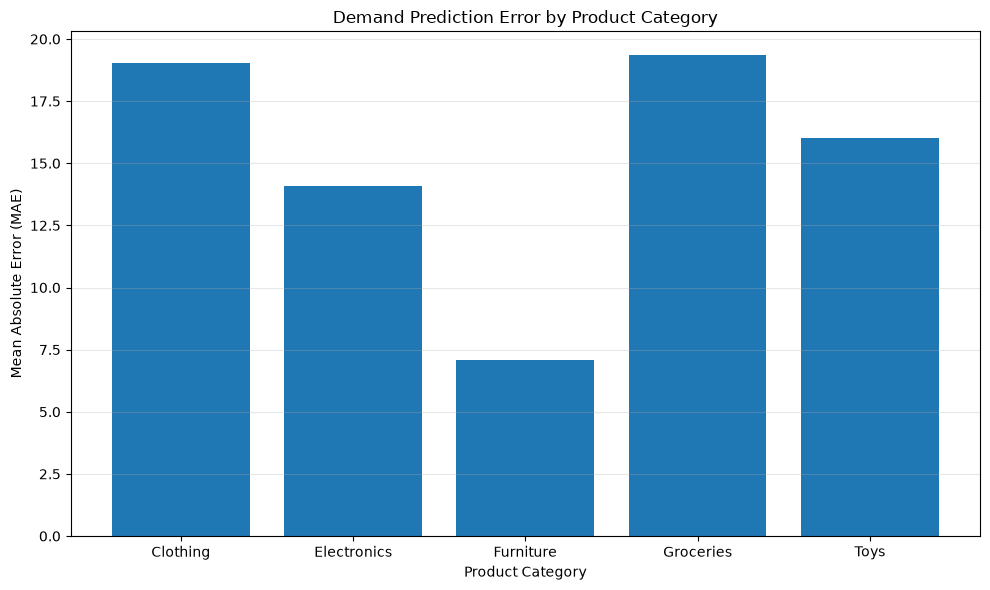

In [5]:
plt.figure(figsize=(10, 6))

plt.bar(
    category_prediction_performance.index,
    category_prediction_performance["MAE"]
)

plt.title("Demand Prediction Error by Product Category")
plt.xlabel("Product Category")
plt.ylabel("Mean Absolute Error (MAE)")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

In [6]:
category_prediction_performance["Average_Error"] = (
    business_df.groupby("Category").apply(
        lambda group: (
            group["Demand"] - group["Predicted_Demand"]
        ).mean(),
        include_groups=False
    )
)

category_prediction_performance[
    ["Average_Actual_Demand",
     "Average_Predicted_Demand",
     "MAE",
     "Average_Error"]
].round(2)

,Average_Actual_Demand,Average_Predicted_Demand,MAE,Average_Error
Category,,,,
Clothing,113.91,113.36,19.05,0.55
Electronics,95.59,96.67,14.08,-1.07
Furniture,72.30,72.38,7.09,-0.08
Groceries,113.67,114.18,19.34,-0.51
Toys,86.46,89.02,16.04,-2.56


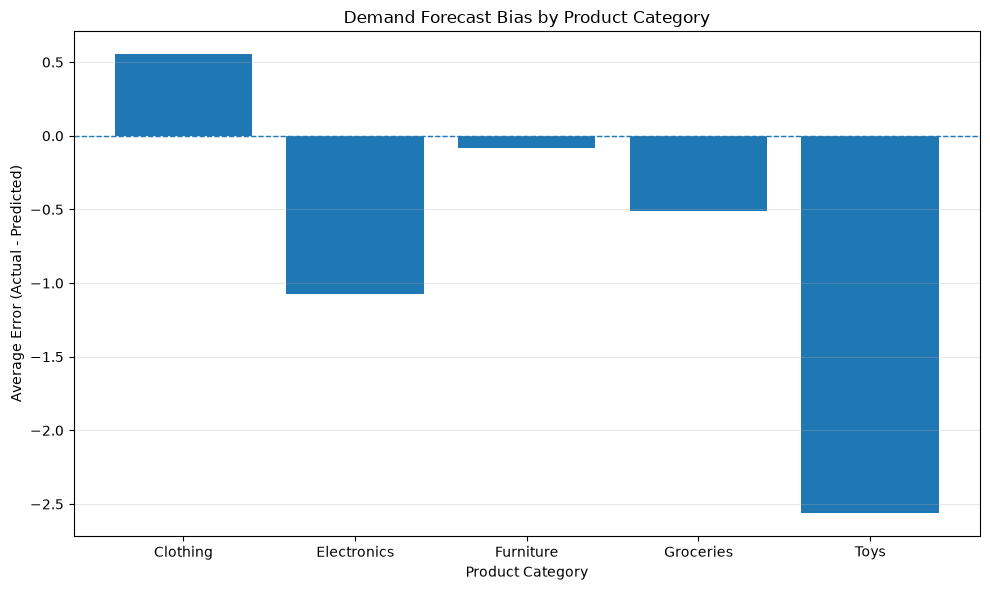

In [7]:
plt.figure(figsize=(10, 6))

plt.bar(
    category_prediction_performance.index,
    category_prediction_performance["Average_Error"]
)

plt.axhline(y=0, linestyle="--", linewidth=1)

plt.title("Demand Forecast Bias by Product Category")
plt.xlabel("Product Category")
plt.ylabel("Average Error (Actual - Predicted)")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

In [8]:
category_demand_summary = business_df.groupby("Category").agg(
    Total_Actual_Demand=("Demand", "sum"),
    Total_Predicted_Demand=("Predicted_Demand", "sum"),
    Average_Actual_Demand=("Demand", "mean"),
    Average_Predicted_Demand=("Predicted_Demand", "mean")
)

category_demand_summary.round(2)

,Total_Actual_Demand,Total_Predicted_Demand,Average_Actual_Demand,Average_Predicted_Demand
Category,,,,
Clothing,277028,275681.99,113.91,113.36
Electronics,174361,176318.08,95.59,96.67
Furniture,197814,198032.29,72.30,72.38
Groceries,691130,694229.04,113.67,114.18
Toys,183978,189429.22,86.46,89.02


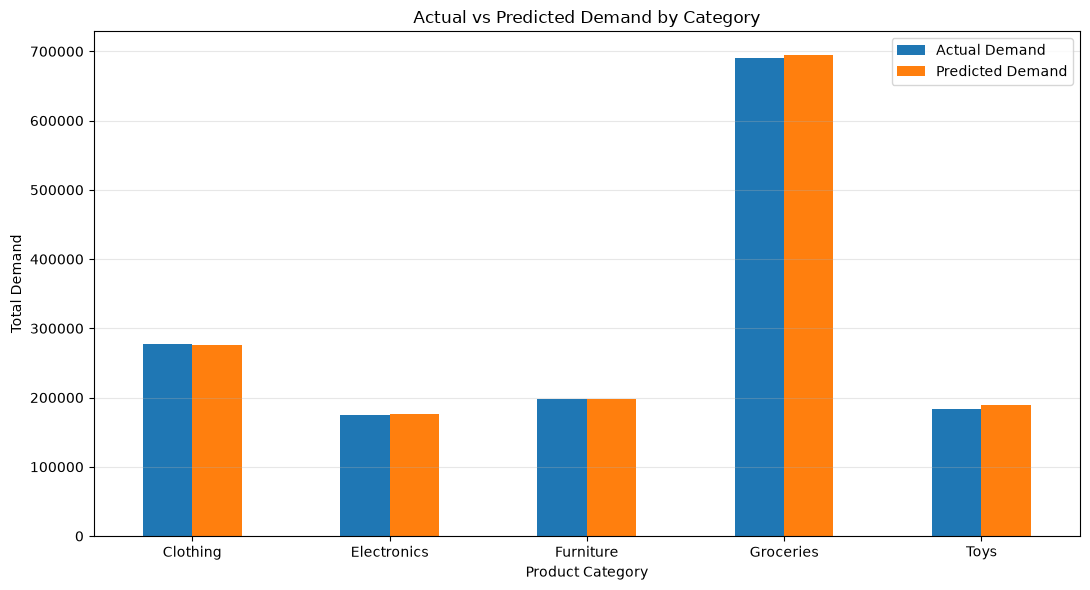

In [9]:
category_demand_summary[
    ["Total_Actual_Demand", "Total_Predicted_Demand"]
].plot(
    kind="bar",
    figsize=(11, 6)
)

plt.title("Actual vs Predicted Demand by Category")
plt.xlabel("Product Category")
plt.ylabel("Total Demand")
plt.xticks(rotation=0)
plt.legend(["Actual Demand", "Predicted Demand"])
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

In [10]:
category_demand_summary["Demand_Share_%"] = (
    category_demand_summary["Total_Actual_Demand"]
    / category_demand_summary["Total_Actual_Demand"].sum()
) * 100

category_demand_summary[
    ["Total_Actual_Demand", "Demand_Share_%"]
].sort_values(
    "Demand_Share_%", ascending=False
).round(2)

,Total_Actual_Demand,Demand_Share_%
Category,,
Groceries,691130,45.34
Clothing,277028,18.17
Furniture,197814,12.98
Toys,183978,12.07
Electronics,174361,11.44


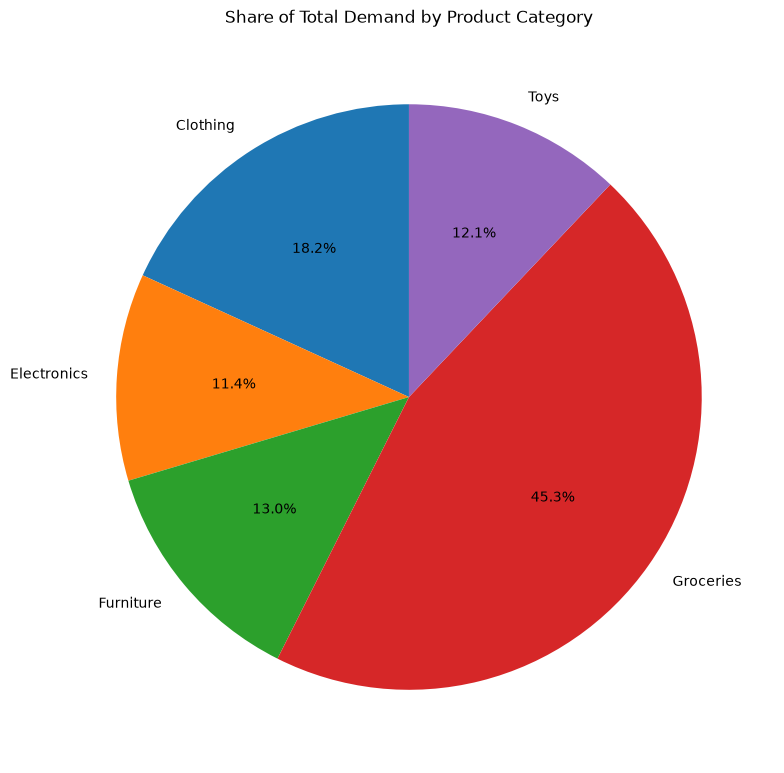

In [11]:
plt.figure(figsize=(8, 8))

plt.pie(
    category_demand_summary["Demand_Share_%"],
    labels=category_demand_summary.index,
    autopct="%1.1f%%",
    startangle=90
)

plt.title("Share of Total Demand by Product Category")
plt.tight_layout()
plt.show()

In [12]:
regional_business_summary = business_df.groupby("Region").agg(
    Total_Actual_Demand=("Demand", "sum"),
    Average_Actual_Demand=("Demand", "mean"),
    Total_Units_Sold=("Units Sold", "sum"),
    Records=("Demand", "count")
)

regional_business_summary.round(2).sort_values(
    "Total_Actual_Demand", ascending=False
)

,Total_Actual_Demand,Average_Actual_Demand,Total_Units_Sold,Records
Region,,,,
North,605424,99.58,518164,6080
South,312346,102.75,267087,3040
East,311175,102.36,266209,3040
West,295366,97.16,254402,3040


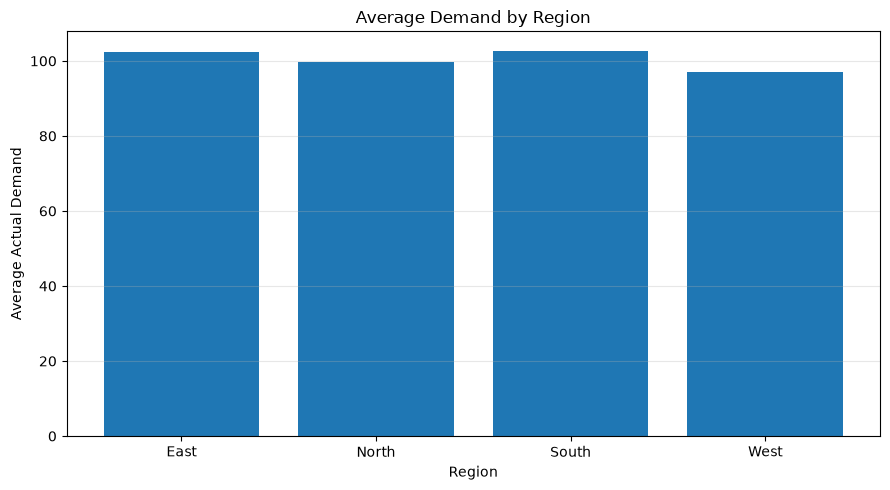

In [13]:
plt.figure(figsize=(9, 5))

plt.bar(
    regional_business_summary.index,
    regional_business_summary["Average_Actual_Demand"]
)

plt.title("Average Demand by Region")
plt.xlabel("Region")
plt.ylabel("Average Actual Demand")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

In [15]:
regional_business_summary["Average_Units_Sold"] = (
    business_df.groupby("Region")["Units Sold"].mean()
)

regional_business_summary[
    ["Average_Actual_Demand", "Average_Units_Sold"]
].round(2)

,Average_Actual_Demand,Average_Units_Sold
Region,,
East,102.36,87.57
North,99.58,85.22
South,102.75,87.86
West,97.16,83.68


In [16]:
regional_business_summary["Average_Demand_Sales_Gap"] = (
    regional_business_summary["Average_Actual_Demand"]
    - regional_business_summary["Average_Units_Sold"]
)

regional_business_summary[
    [
        "Average_Actual_Demand",
        "Average_Units_Sold",
        "Average_Demand_Sales_Gap"
    ]
].round(2)

,Average_Actual_Demand,Average_Units_Sold,Average_Demand_Sales_Gap
Region,,,
East,102.36,87.57,14.79
North,99.58,85.22,14.35
South,102.75,87.86,14.89
West,97.16,83.68,13.48


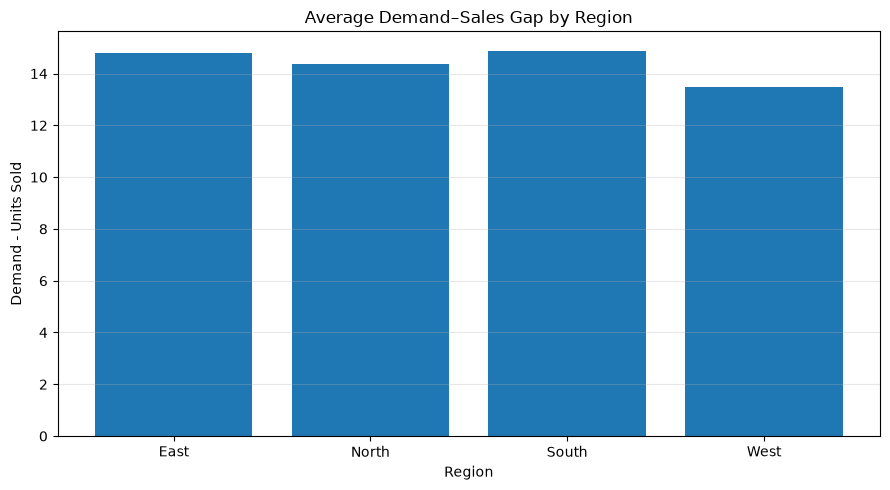

In [17]:
plt.figure(figsize=(9, 5))

plt.bar(
    regional_business_summary.index,
    regional_business_summary["Average_Demand_Sales_Gap"]
)

plt.title("Average Demand–Sales Gap by Region")
plt.xlabel("Region")
plt.ylabel("Demand - Units Sold")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

In [18]:
regional_inventory_summary = business_df.groupby("Region").agg(
    Average_Inventory=("Inventory Level", "mean"),
    Average_Units_Sold=("Units Sold", "mean"),
    Total_Inventory=("Inventory Level", "sum"),
    Total_Units_Sold=("Units Sold", "sum")
)

regional_inventory_summary.round(2)

,Average_Inventory,Average_Units_Sold,Total_Inventory,Total_Units_Sold
Region,,,,
East,314.42,87.57,955839,266209
North,270.70,85.22,1645838,518164
South,323.70,87.86,984044,267087
West,287.96,83.68,875413,254402


In [19]:
regional_inventory_summary["Inventory_to_Sales_Ratio"] = (
    regional_inventory_summary["Average_Inventory"]
    / regional_inventory_summary["Average_Units_Sold"]
)

regional_inventory_summary[
    [
        "Average_Inventory",
        "Average_Units_Sold",
        "Inventory_to_Sales_Ratio"
    ]
].round(2)

,Average_Inventory,Average_Units_Sold,Inventory_to_Sales_Ratio
Region,,,
East,314.42,87.57,3.59
North,270.70,85.22,3.18
South,323.70,87.86,3.68
West,287.96,83.68,3.44


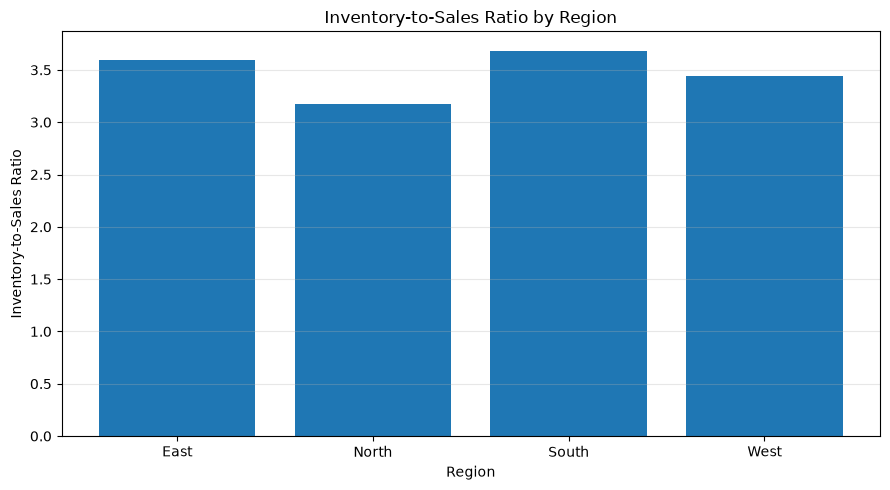

In [20]:
plt.figure(figsize=(9, 5))

plt.bar(
    regional_inventory_summary.index,
    regional_inventory_summary["Inventory_to_Sales_Ratio"]
)

plt.title("Inventory-to-Sales Ratio by Region")
plt.xlabel("Region")
plt.ylabel("Inventory-to-Sales Ratio")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

In [21]:
category_inventory_summary = business_df.groupby("Category").agg(
    Average_Inventory=("Inventory Level", "mean"),
    Average_Units_Sold=("Units Sold", "mean"),
    Total_Inventory=("Inventory Level", "sum"),
    Total_Units_Sold=("Units Sold", "sum")
)

category_inventory_summary.round(2).sort_values(
    "Average_Inventory", ascending=False
)

,Average_Inventory,Average_Units_Sold,Total_Inventory,Total_Units_Sold
Category,,,,
Groceries,344.12,97.07,2092245,590184
Clothing,286.47,96.08,696698,233670
Electronics,279.66,82.62,510105,150693
Furniture,249.09,63.71,681497,174302
Toys,225.84,73.78,480589,157013


In [22]:
category_inventory_summary["Inventory_to_Sales_Ratio"] = (
    category_inventory_summary["Average_Inventory"]
    / category_inventory_summary["Average_Units_Sold"]
)

category_inventory_summary[
    [
        "Average_Inventory",
        "Average_Units_Sold",
        "Inventory_to_Sales_Ratio"
    ]
].round(2).sort_values(
    "Inventory_to_Sales_Ratio", ascending=False
)

,Average_Inventory,Average_Units_Sold,Inventory_to_Sales_Ratio
Category,,,
Furniture,249.09,63.71,3.91
Groceries,344.12,97.07,3.55
Electronics,279.66,82.62,3.39
Toys,225.84,73.78,3.06
Clothing,286.47,96.08,2.98


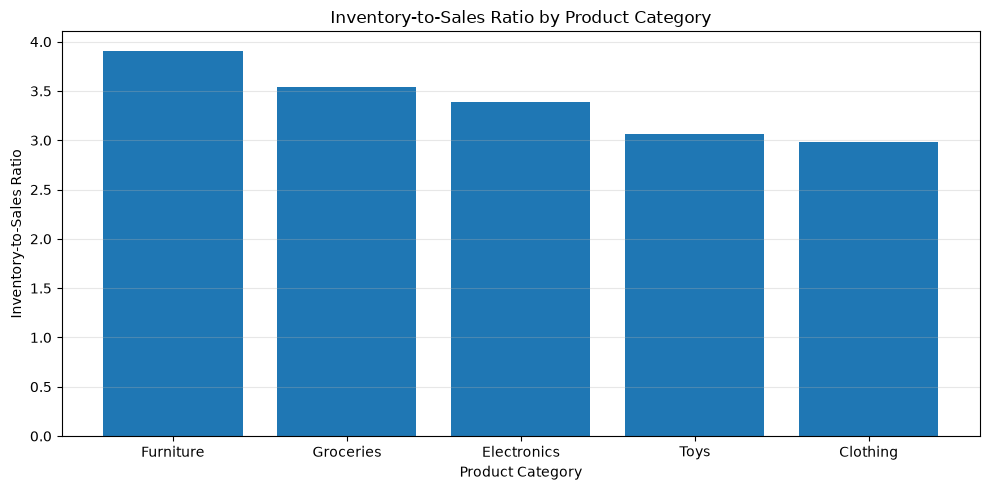

In [23]:
plt.figure(figsize=(10, 5))

plt.bar(
    category_inventory_summary.sort_values(
        "Inventory_to_Sales_Ratio",
        ascending=False
    ).index,
    category_inventory_summary.sort_values(
        "Inventory_to_Sales_Ratio",
        ascending=False
    )["Inventory_to_Sales_Ratio"]
)

plt.title("Inventory-to-Sales Ratio by Product Category")
plt.xlabel("Product Category")
plt.ylabel("Inventory-to-Sales Ratio")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

In [24]:
category_inventory_demand = business_df.groupby("Category").agg(
    Average_Inventory=("Inventory Level", "mean"),
    Average_Demand=("Demand", "mean"),
    Average_Units_Sold=("Units Sold", "mean")
)

category_inventory_demand.round(2)

,Average_Inventory,Average_Demand,Average_Units_Sold
Category,,,
Clothing,286.47,113.91,96.08
Electronics,279.66,95.59,82.62
Furniture,249.09,72.30,63.71
Groceries,344.12,113.67,97.07
Toys,225.84,86.46,73.78


In [25]:
category_inventory_demand["Inventory_Demand_Gap"] = (
    category_inventory_demand["Average_Inventory"]
    - category_inventory_demand["Average_Demand"]
)

category_inventory_demand[
    [
        "Average_Inventory",
        "Average_Demand",
        "Inventory_Demand_Gap"
    ]
].round(2).sort_values(
    "Inventory_Demand_Gap", ascending=False
)

,Average_Inventory,Average_Demand,Inventory_Demand_Gap
Category,,,
Groceries,344.12,113.67,230.45
Electronics,279.66,95.59,184.07
Furniture,249.09,72.30,176.78
Clothing,286.47,113.91,172.56
Toys,225.84,86.46,139.38


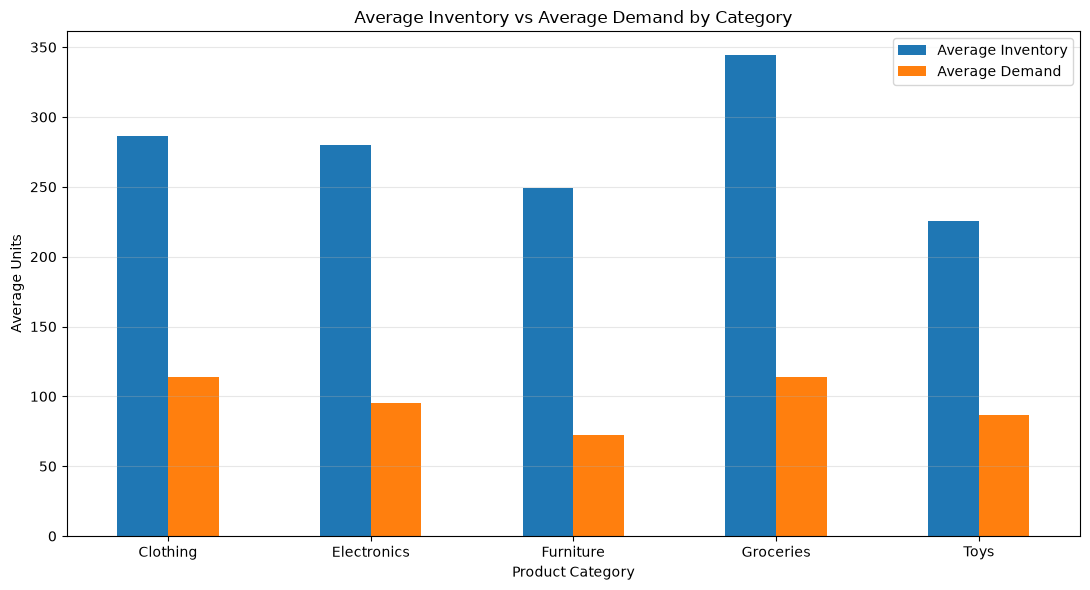

In [26]:
category_inventory_demand[
    ["Average_Inventory", "Average_Demand"]
].plot(
    kind="bar",
    figsize=(11, 6)
)

plt.title("Average Inventory vs Average Demand by Category")
plt.xlabel("Product Category")
plt.ylabel("Average Units")
plt.xticks(rotation=0)
plt.legend(["Average Inventory", "Average Demand"])
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

In [27]:
business_df["Month"] = business_df["Date"].dt.to_period("M")

monthly_demand_summary = business_df.groupby("Month").agg(
    Total_Actual_Demand=("Demand", "sum"),
    Total_Predicted_Demand=("Predicted_Demand", "sum"),
    Average_Actual_Demand=("Demand", "mean"),
    Average_Predicted_Demand=("Predicted_Demand", "mean")
)

monthly_demand_summary.round(2)


,Total_Actual_Demand,Total_Predicted_Demand,Average_Actual_Demand,Average_Predicted_Demand
Month,,,,
2023-09,320325,323462.10,106.78,107.82
2023-10,262590,263208.58,84.71,84.91
2023-11,320848,322356.03,106.95,107.45
2023-12,326389,326763.07,105.29,105.41
2024-01,294159,297900.84,98.05,99.30


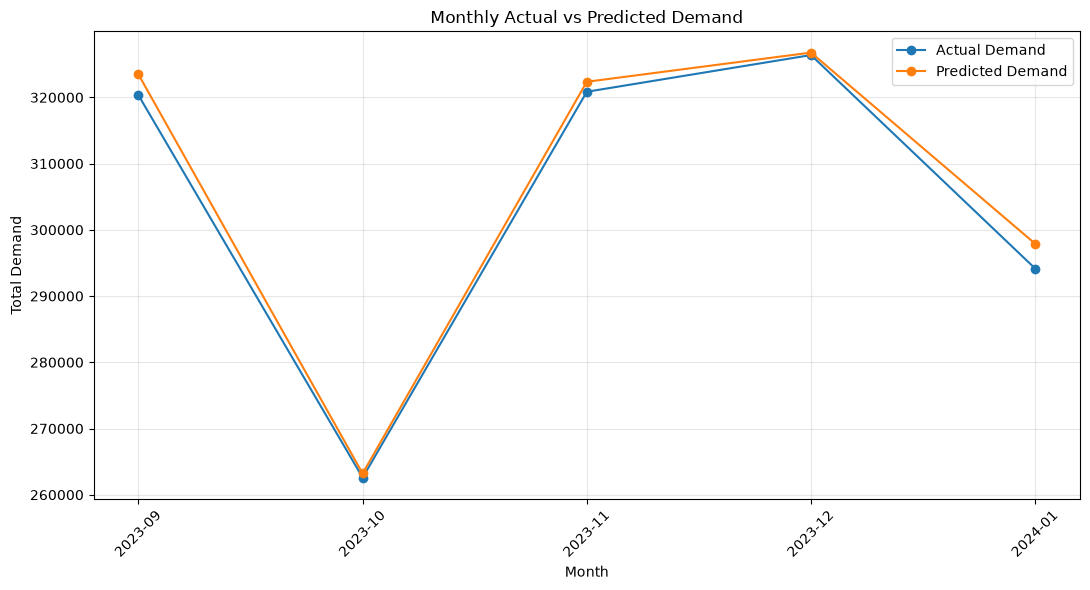

In [28]:
plt.figure(figsize=(11, 6))

plt.plot(
    monthly_demand_summary.index.astype(str),
    monthly_demand_summary["Total_Actual_Demand"],
    marker="o",
    label="Actual Demand"
)

plt.plot(
    monthly_demand_summary.index.astype(str),
    monthly_demand_summary["Total_Predicted_Demand"],
    marker="o",
    label="Predicted Demand"
)

plt.title("Monthly Actual vs Predicted Demand")
plt.xlabel("Month")
plt.ylabel("Total Demand")
plt.legend()
plt.grid(alpha=0.3)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [29]:
monthly_demand_summary["Demand_Forecast_Error"] = (
    monthly_demand_summary["Total_Actual_Demand"]
    - monthly_demand_summary["Total_Predicted_Demand"]
)

monthly_demand_summary[
    [
        "Total_Actual_Demand",
        "Total_Predicted_Demand",
        "Demand_Forecast_Error"
    ]
].round(2)

,Total_Actual_Demand,Total_Predicted_Demand,Demand_Forecast_Error
Month,,,
2023-09,320325,323462.10,-3137.10
2023-10,262590,263208.58,-618.58
2023-11,320848,322356.03,-1508.03
2023-12,326389,326763.07,-374.07
2024-01,294159,297900.84,-3741.84


In [30]:
monthly_demand_summary["Forecast_Error_%"] = (
    monthly_demand_summary["Demand_Forecast_Error"]
    / monthly_demand_summary["Total_Actual_Demand"]
) * 100

monthly_demand_summary[
    ["Demand_Forecast_Error", "Forecast_Error_%"]
].round(2)

,Demand_Forecast_Error,Forecast_Error_%
Month,,
2023-09,-3137.10,-0.98
2023-10,-618.58,-0.24
2023-11,-1508.03,-0.47
2023-12,-374.07,-0.11
2024-01,-3741.84,-1.27


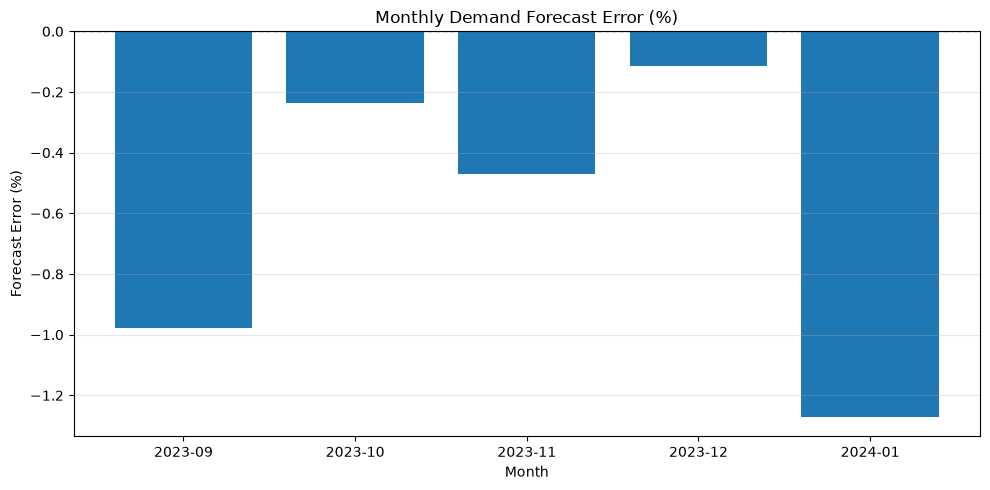

In [31]:
plt.figure(figsize=(10, 5))

plt.bar(
    monthly_demand_summary.index.astype(str),
    monthly_demand_summary["Forecast_Error_%"]
)

plt.axhline(y=0, linestyle="--", linewidth=1)

plt.title("Monthly Demand Forecast Error (%)")
plt.xlabel("Month")
plt.ylabel("Forecast Error (%)")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

In [32]:
business_df["Absolute_Error"] = (
    business_df["Demand"] - business_df["Predicted_Demand"]
).abs()

monthly_prediction_accuracy = business_df.groupby("Month").agg(
    Monthly_MAE=("Absolute_Error", "mean"),
    Average_Actual_Demand=("Demand", "mean"),
    Records=("Demand", "count")
)

monthly_prediction_accuracy.round(2)

,Monthly_MAE,Average_Actual_Demand,Records
Month,,,
2023-09,15.84,106.78,3000
2023-10,14.93,84.71,3100
2023-11,16.08,106.95,3000
2023-12,16.93,105.29,3100
2024-01,16.21,98.05,3000


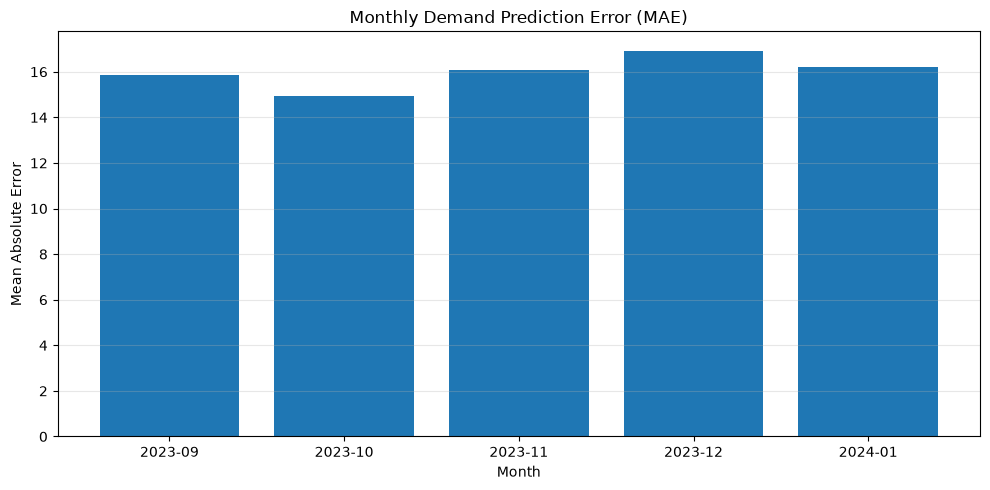

In [33]:
plt.figure(figsize=(10, 5))

plt.bar(
    monthly_prediction_accuracy.index.astype(str),
    monthly_prediction_accuracy["Monthly_MAE"]
)

plt.title("Monthly Demand Prediction Error (MAE)")
plt.xlabel("Month")
plt.ylabel("Mean Absolute Error")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

In [34]:
category_region_performance = business_df.groupby(
    ["Category", "Region"]
).apply(
    lambda group: pd.Series({
        "Actual_Demand": group["Demand"].mean(),
        "Predicted_Demand": group["Predicted_Demand"].mean(),
        "MAE": np.mean(
            np.abs(group["Demand"] - group["Predicted_Demand"])
        ),
        "Records": len(group)
    }),
    include_groups=False
)

category_region_performance.round(2)

Actual_Demand  Predicted_Demand    MAE  Records
Category    Region                                                 
Clothing    East           111.07            113.32  17.27    304.0
            North          124.53            119.63  18.50    608.0
            South          110.17            112.04  19.74    760.0
            West           110.29            109.68  19.50    760.0
Electronics East           104.05            108.48  14.25    456.0
            North           92.95             91.40  14.77    760.0
            South           89.92             92.26  13.91    456.0
            West           100.43            100.78  10.68    152.0
Furniture   East            73.91             72.54   7.61    456.0
            North           72.89             72.04   6.96   1064.0
            South           69.14             75.06   8.60    152.0
            West            71.48             72.27   6.78   1064.0
Groceries   East           114.21            113.86  19.16   1368.0
            North          113.91            114.01  19.42   2432.0
            South          113.17            115.62  17.08   1216.0
            West           113.00            113.34  21.98   1064.0
Toys        East            87.77             87.37  14.22    456.0
            North           85.92             89.81  16.03   1216.0
            South           86.58             88.55  17.86    456.0

In [35]:
category_region_performance.sort_values(
    "MAE",
    ascending=False
).head(5).round(2)

Actual_Demand  Predicted_Demand    MAE  Records
Category  Region                                                 
Groceries West           113.00            113.34  21.98   1064.0
Clothing  South          110.17            112.04  19.74    760.0
          West           110.29            109.68  19.50    760.0
Groceries North          113.91            114.01  19.42   2432.0
          East           114.21            113.86  19.16   1368.0

In [36]:
category_region_performance.sort_values(
    "MAE",
    ascending=True
).head(5).round(2)

Actual_Demand  Predicted_Demand    MAE  Records
Category    Region                                                 
Furniture   West            71.48             72.27   6.78   1064.0
            North           72.89             72.04   6.96   1064.0
            East            73.91             72.54   7.61    456.0
            South           69.14             75.06   8.60    152.0
Electronics West           100.43            100.78  10.68    152.0

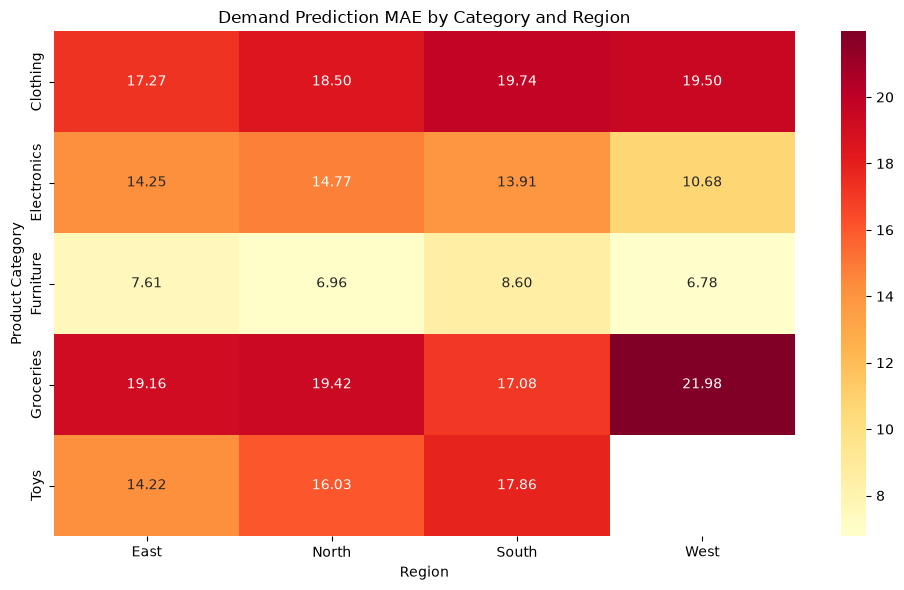

In [37]:
mae_heatmap = category_region_performance["MAE"].unstack()

plt.figure(figsize=(10, 6))

sns.heatmap(
    mae_heatmap,
    annot=True,
    fmt=".2f",
    cmap="YlOrRd"
)

plt.title("Demand Prediction MAE by Category and Region")
plt.xlabel("Region")
plt.ylabel("Product Category")
plt.tight_layout()
plt.show()

In [38]:
store_business_summary = business_df.groupby("Store ID").agg(
    Total_Demand=("Demand", "sum"),
    Average_Demand=("Demand", "mean"),
    Total_Units_Sold=("Units Sold", "sum"),
    Average_Inventory=("Inventory Level", "mean"),
    Records=("Demand", "count")
)

store_business_summary.round(2).sort_values(
    "Total_Demand", ascending=False
)

,Total_Demand,Average_Demand,Total_Units_Sold,Average_Inventory,Records
Store ID,,,,,
S002,312346,102.75,267087,323.70,3040
S003,311175,102.36,266209,314.42,3040
S005,307244,101.07,262096,271.02,3040
S001,298180,98.09,256068,270.38,3040
S004,295366,97.16,254402,287.96,3040


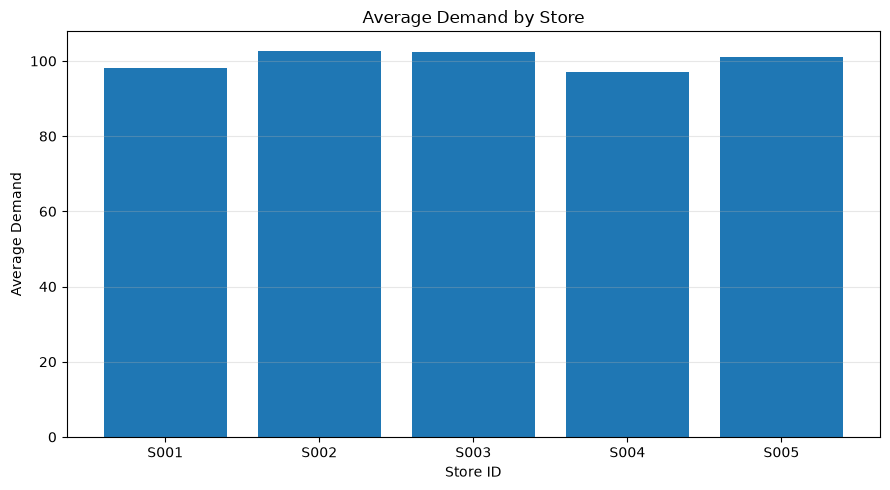

In [39]:
plt.figure(figsize=(9, 5))

plt.bar(
    store_business_summary.index,
    store_business_summary["Average_Demand"]
)

plt.title("Average Demand by Store")
plt.xlabel("Store ID")
plt.ylabel("Average Demand")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

In [40]:
store_inventory_summary = business_df.groupby("Store ID").agg(
    Average_Inventory=("Inventory Level", "mean"),
    Average_Units_Sold=("Units Sold", "mean"),
    Total_Inventory=("Inventory Level", "sum"),
    Total_Units_Sold=("Units Sold", "sum")
)

store_inventory_summary["Inventory_to_Sales_Ratio"] = (
    store_inventory_summary["Total_Inventory"] /
    store_inventory_summary["Total_Units_Sold"]
)

store_inventory_summary.round(2).sort_values(
    "Inventory_to_Sales_Ratio",
    ascending=False
)

,Average_Inventory,Average_Units_Sold,Total_Inventory,Total_Units_Sold,Inventory_to_Sales_Ratio
Store ID,,,,,
S002,323.70,87.86,984044,267087,3.68
S003,314.42,87.57,955839,266209,3.59
S004,287.96,83.68,875413,254402,3.44
S001,270.38,84.23,821948,256068,3.21
S005,271.02,86.22,823890,262096,3.14


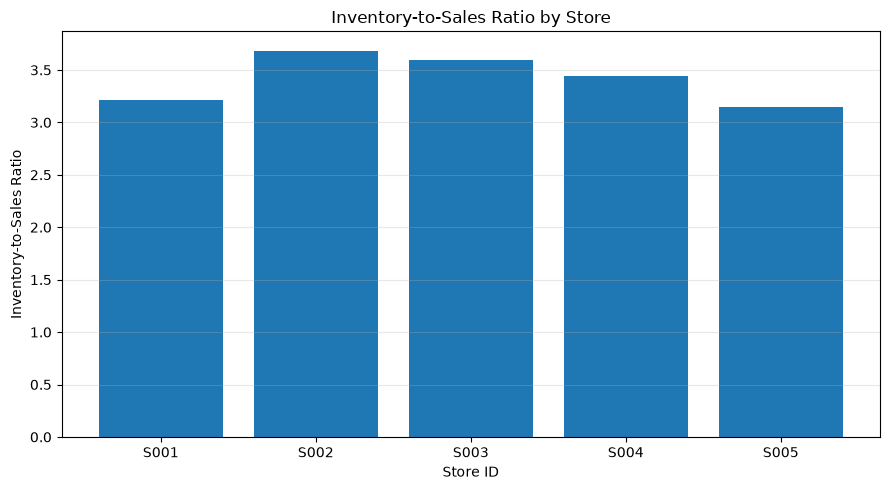

In [41]:
plt.figure(figsize=(9, 5))

plt.bar(
    store_inventory_summary.index,
    store_inventory_summary["Inventory_to_Sales_Ratio"]
)

plt.title("Inventory-to-Sales Ratio by Store")
plt.xlabel("Store ID")
plt.ylabel("Inventory-to-Sales Ratio")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

In [42]:
store_performance_ranking = store_business_summary[
    ["Average_Demand", "Average_Inventory", "Total_Units_Sold"]
].copy()

store_performance_ranking["Demand_Rank"] = (
    store_performance_ranking["Average_Demand"]
    .rank(ascending=False, method="min")
)

store_performance_ranking["Sales_Rank"] = (
    store_performance_ranking["Total_Units_Sold"]
    .rank(ascending=False, method="min")
)

store_performance_ranking.sort_values("Demand_Rank").round(2)

,Average_Demand,Average_Inventory,Total_Units_Sold,Demand_Rank,Sales_Rank
Store ID,,,,,
S002,102.75,323.70,267087,1.0,1.0
S003,102.36,314.42,266209,2.0,2.0
S005,101.07,271.02,262096,3.0,3.0
S001,98.09,270.38,256068,4.0,4.0
S004,97.16,287.96,254402,5.0,5.0


In [46]:
pricing_df = business_df.copy()

pricing_df["Estimated_Selling_Price"] = (
    pricing_df["Price"] *
    (1 - pricing_df["Discount"] / 100)
)

assumed_cost_percentages = {
    "Clothing": 0.60,
    "Electronics": 0.70,
    "Furniture": 0.55,
    "Groceries": 0.75,
    "Toys": 0.65
}

pricing_df["Unit_Cost"] = (
    pricing_df["Category"].map(assumed_cost_percentages)
    * pricing_df["Price"]
)

pricing_df["Estimated_Sales_Value"] = (
    pricing_df["Estimated_Selling_Price"]
    * pricing_df["Units Sold"]
)

pricing_df["Estimated_Total_Profit"] = (
    pricing_df["Estimated_Selling_Price"]
    - pricing_df["Unit_Cost"]
) * pricing_df["Units Sold"]

print(pricing_df.shape)
print(pricing_df[[
    "Estimated_Sales_Value",
    "Estimated_Total_Profit"
]].head())

(15200, 23)
       Estimated_Sales_Value  Estimated_Total_Profit
60800              4592.8050                  0.0000
60801              3001.2840                500.2140
60802             12393.8100               5577.2145
60803              1469.3490                244.8915
60804              3465.6965                407.7290


In [7]:
store_profitability = pricing_df.groupby("Store ID").agg(
    Estimated_Sales=("Estimated_Sales_Value", "sum"),
    Estimated_Profit=("Estimated_Total_Profit", "sum"),
    Units_Sold=("Units Sold", "sum")
)

store_profitability["Profit_Margin"] = (
    store_profitability["Estimated_Profit"] /
    store_profitability["Estimated_Sales"] * 100
)

store_profitability.round(2).sort_values(
    "Estimated_Profit", ascending=False
)

,Estimated_Sales,Estimated_Profit,Units_Sold,Profit_Margin
Store ID,,,,
S004,16747438.77,5487344.62,254402,32.77
S001,15890559.26,4571556.26,256068,28.77
S003,17178197.00,4380963.96,266209,25.50
S002,15973817.28,3959400.93,267087,24.79
S005,13852869.34,3469549.96,262096,25.05


In [8]:
store_profitability = pricing_df.groupby("Store ID").agg(
    Estimated_Sales=("Estimated_Sales_Value", "sum"),
    Estimated_Profit=("Estimated_Total_Profit", "sum"),
    Units_Sold=("Units Sold", "sum")
)

store_profitability["Profit_Margin"] = (
    store_profitability["Estimated_Profit"] /
    store_profitability["Estimated_Sales"] * 100
)

store_profitability.round(2).sort_values(
    "Estimated_Profit", ascending=False
)

,Estimated_Sales,Estimated_Profit,Units_Sold,Profit_Margin
Store ID,,,,
S004,16747438.77,5487344.62,254402,32.77
S001,15890559.26,4571556.26,256068,28.77
S003,17178197.00,4380963.96,266209,25.50
S002,15973817.28,3959400.93,267087,24.79
S005,13852869.34,3469549.96,262096,25.05


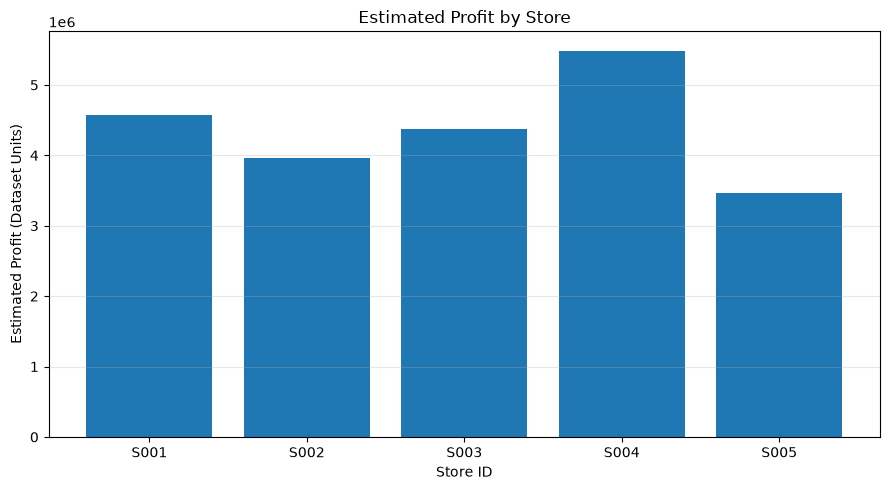

In [9]:
plt.figure(figsize=(9, 5))

plt.bar(
    store_profitability.index,
    store_profitability["Estimated_Profit"]
)

plt.title("Estimated Profit by Store")
plt.xlabel("Store ID")
plt.ylabel("Estimated Profit (Dataset Units)")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

In [10]:
import matplotlib.pyplot as plt

In [11]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("../Data/Raw/retail_demand.csv")

df["Date"] = pd.to_datetime(df["Date"])
df = df.sort_values("Date").reset_index(drop=True)

split_date = df["Date"].unique()[
    int(len(df["Date"].unique()) * 0.80)
]

test_df = df[df["Date"] >= split_date].copy()

business_df = test_df.copy()

predictions = pd.read_csv("../Reports/final_demand_predictions.csv")
business_df["Predicted_Demand"] = predictions["Predicted_Demand"].values

pricing_df = business_df.copy()

pricing_df["Estimated_Selling_Price"] = (
    pricing_df["Price"] * (1 - pricing_df["Discount"] / 100)
)

assumed_cost_percentages = {
    "Clothing": 0.60,
    "Electronics": 0.70,
    "Furniture": 0.55,
    "Groceries": 0.75,
    "Toys": 0.65
}

pricing_df["Unit_Cost"] = (
    pricing_df["Category"].map(assumed_cost_percentages)
    * pricing_df["Price"]
)

pricing_df["Estimated_Sales_Value"] = (
    pricing_df["Estimated_Selling_Price"]
    * pricing_df["Units Sold"]
)

pricing_df["Estimated_Total_Profit"] = (
    pricing_df["Estimated_Selling_Price"]
    - pricing_df["Unit_Cost"]
) * pricing_df["Units Sold"]

print("Pricing data recreated:", pricing_df.shape)

Pricing data recreated: (15200, 21)


In [12]:
store_profitability = pricing_df.groupby("Store ID").agg(
    Estimated_Sales=("Estimated_Sales_Value", "sum"),
    Estimated_Profit=("Estimated_Total_Profit", "sum"),
    Units_Sold=("Units Sold", "sum")
)

store_profitability["Profit_Margin"] = (
    store_profitability["Estimated_Profit"] /
    store_profitability["Estimated_Sales"] * 100
)

store_profitability.round(2)

,Estimated_Sales,Estimated_Profit,Units_Sold,Profit_Margin
Store ID,,,,
S001,15890559.26,4571556.26,256068,28.77
S002,15973817.28,3959400.93,267087,24.79
S003,17178197.00,4380963.96,266209,25.50
S004,16747438.77,5487344.62,254402,32.77
S005,13852869.34,3469549.96,262096,25.05


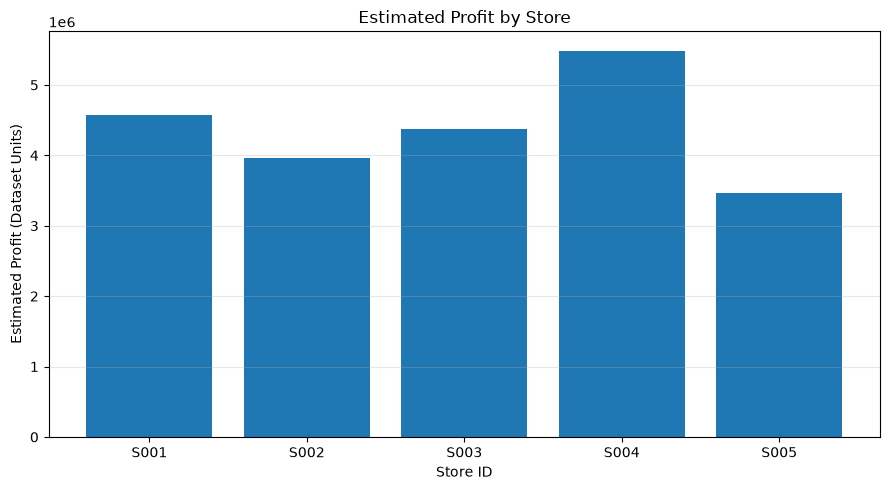

In [13]:
plt.figure(figsize=(9, 5))

plt.bar(
    store_profitability.index,
    store_profitability["Estimated_Profit"]
)

plt.title("Estimated Profit by Store")
plt.xlabel("Store ID")
plt.ylabel("Estimated Profit (Dataset Units)")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

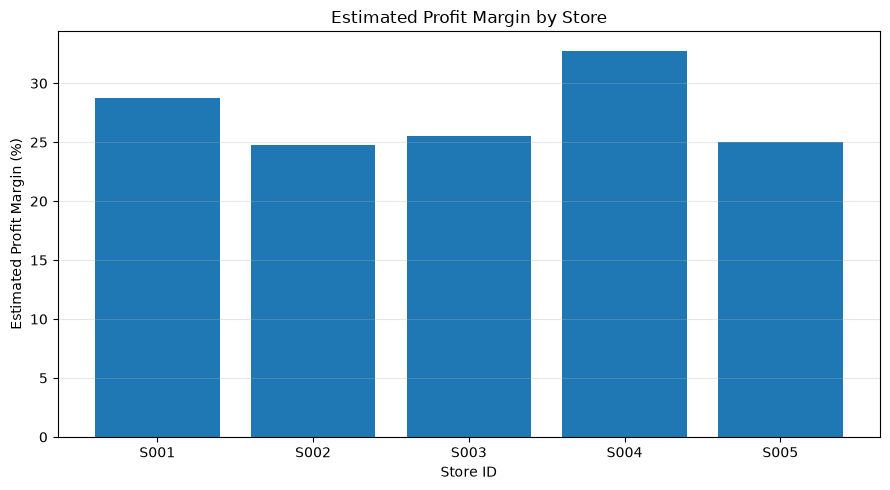

In [14]:
plt.figure(figsize=(9, 5))

plt.bar(
    store_profitability.index,
    store_profitability["Profit_Margin"]
)

plt.title("Estimated Profit Margin by Store")
plt.xlabel("Store ID")
plt.ylabel("Estimated Profit Margin (%)")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

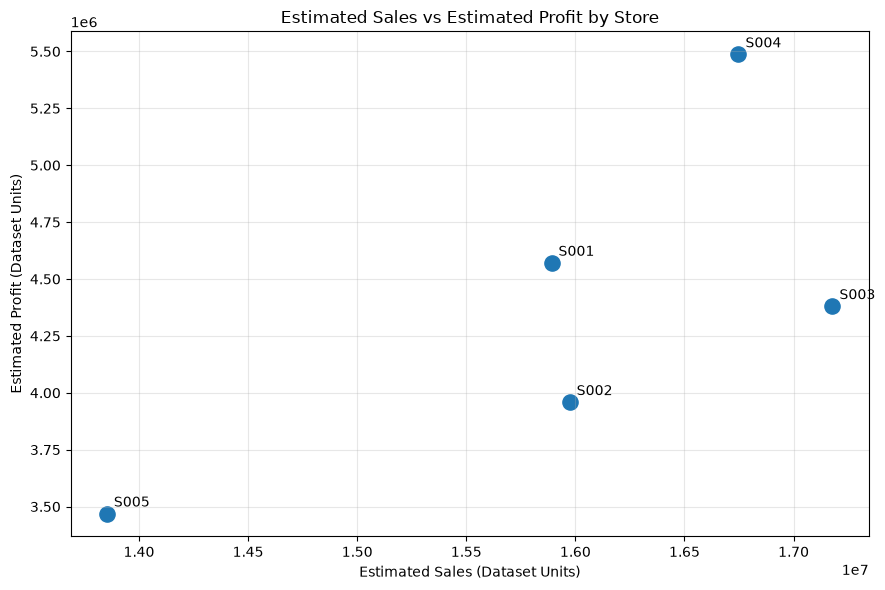

In [15]:
plt.figure(figsize=(9, 6))

plt.scatter(
    store_profitability["Estimated_Sales"],
    store_profitability["Estimated_Profit"],
    s=120
)

for store in store_profitability.index:
    plt.annotate(
        store,
        (
            store_profitability.loc[store, "Estimated_Sales"],
            store_profitability.loc[store, "Estimated_Profit"]
        ),
        xytext=(5, 5),
        textcoords="offset points"
    )

plt.title("Estimated Sales vs Estimated Profit by Store")
plt.xlabel("Estimated Sales (Dataset Units)")
plt.ylabel("Estimated Profit (Dataset Units)")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [16]:
store_category_profit = pricing_df.pivot_table(
    index="Store ID",
    columns="Category",
    values="Estimated_Total_Profit",
    aggfunc="sum"
)

store_category_profit.round(2)

Category,Clothing,Electronics,Furniture,Groceries,Toys
Store ID,,,,,
S001,1129593.26,552376.64,1779941.08,810248.09,299397.19
S002,1478065.83,670122.84,411198.89,1168180.20,231833.18
S003,861288.32,893011.77,1207563.19,1189561.84,229538.84
S004,1779782.84,292108.59,2959055.57,456397.62,NaN
S005,103495.53,298377.66,1453111.17,1250433.25,364132.36


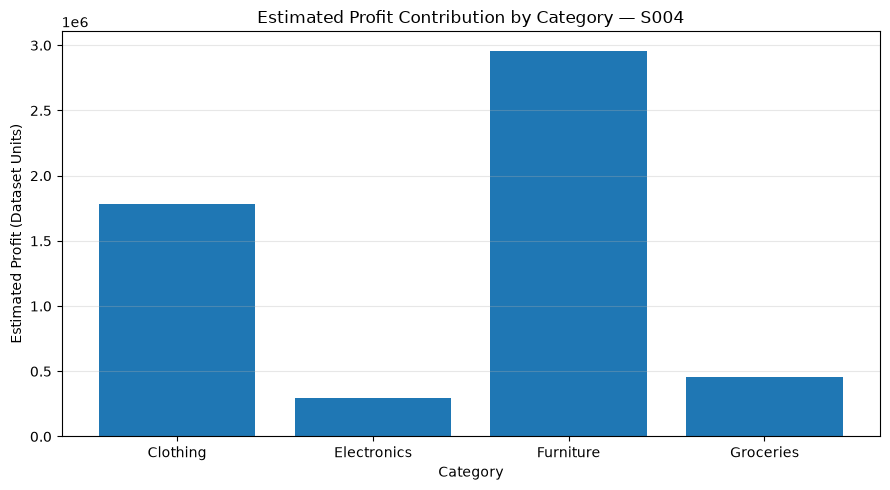

In [17]:
s004_category_profit = store_category_profit.loc["S004"].dropna()

plt.figure(figsize=(9, 5))

plt.bar(
    s004_category_profit.index,
    s004_category_profit.values
)

plt.title("Estimated Profit Contribution by Category — S004")
plt.xlabel("Category")
plt.ylabel("Estimated Profit (Dataset Units)")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

In [18]:
store_category_profit_share = (
    store_category_profit.div(
        store_category_profit.sum(axis=1),
        axis=0
    ) * 100
)

store_category_profit_share.round(2)

Category,Clothing,Electronics,Furniture,Groceries,Toys
Store ID,,,,,
S001,24.71,12.08,38.94,17.72,6.55
S002,37.33,16.92,10.39,29.50,5.86
S003,19.66,20.38,27.56,27.15,5.24
S004,32.43,5.32,53.93,8.32,NaN
S005,2.98,8.60,41.88,36.04,10.50


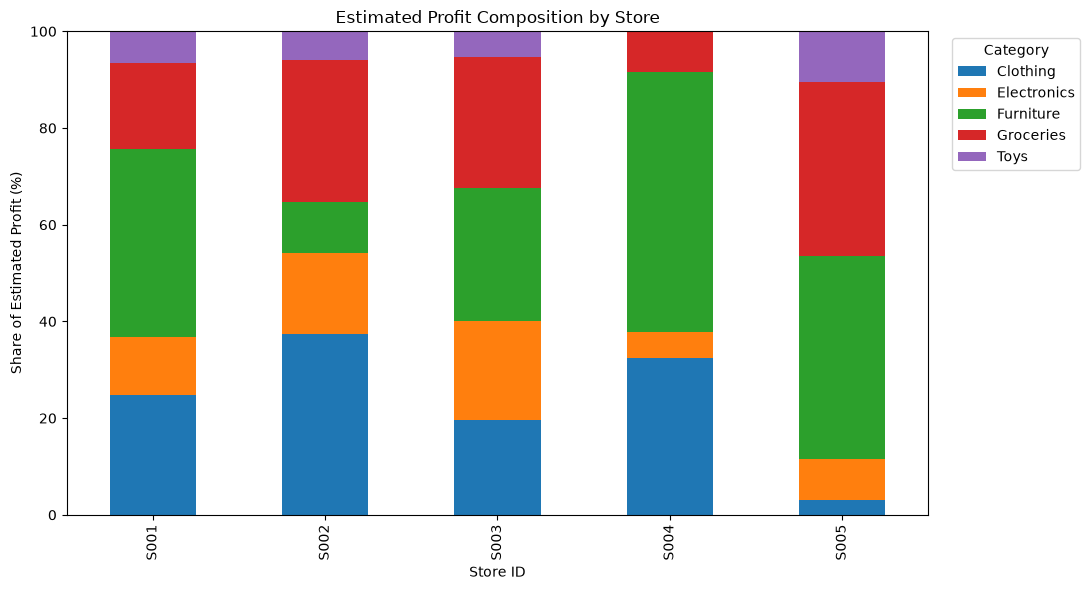

In [19]:
store_category_profit_share.plot(
    kind="bar",
    stacked=True,
    figsize=(11, 6)
)

plt.title("Estimated Profit Composition by Store")
plt.xlabel("Store ID")
plt.ylabel("Share of Estimated Profit (%)")
plt.legend(title="Category", bbox_to_anchor=(1.02, 1))
plt.tight_layout()
plt.show()

In [20]:
top_category_by_store = store_category_profit.idxmax(axis=1)

top_profit_by_store = store_category_profit.max(axis=1)

store_top_category = pd.DataFrame({
    "Top_Profit_Category": top_category_by_store,
    "Estimated_Profit": top_profit_by_store
})

store_top_category.round(2)

,Top_Profit_Category,Estimated_Profit
Store ID,,
S001,Furniture,1779941.08
S002,Clothing,1478065.83
S003,Furniture,1207563.19
S004,Furniture,2959055.57
S005,Furniture,1453111.17


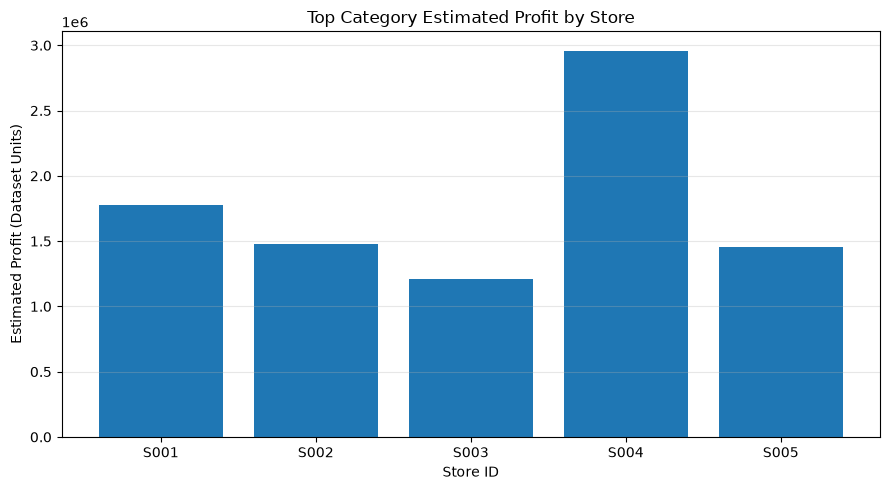

In [21]:
plt.figure(figsize=(9, 5))

plt.bar(
    store_top_category.index,
    store_top_category["Estimated_Profit"]
)

plt.title("Top Category Estimated Profit by Store")
plt.xlabel("Store ID")
plt.ylabel("Estimated Profit (Dataset Units)")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

In [22]:
category_profitability_summary = pricing_df.groupby("Category").agg(
    Total_Units_Sold=("Units Sold", "sum"),
    Estimated_Sales=("Estimated_Sales_Value", "sum"),
    Estimated_Profit=("Estimated_Total_Profit", "sum")
)

category_profitability_summary["Profit_Margin"] = (
    category_profitability_summary["Estimated_Profit"] /
    category_profitability_summary["Estimated_Sales"] * 100
)

category_profitability_summary.round(2).sort_values(
    "Estimated_Profit", ascending=False
)

,Total_Units_Sold,Estimated_Sales,Estimated_Profit,Profit_Margin
Category,,,,
Furniture,174302,19861809.80,7810869.90,39.33
Clothing,233670,15808236.35,5352225.77,33.86
Groceries,590184,28190121.84,4874821.01,17.29
Electronics,150693,11807907.68,2705997.50,22.92
Toys,157013,3974805.98,1124901.56,28.30


In [23]:
category_profitability_summary["Profit_Contribution_%"] = (
    category_profitability_summary["Estimated_Profit"] /
    category_profitability_summary["Estimated_Profit"].sum()
) * 100

category_profitability_summary.round(2).sort_values(
    "Profit_Contribution_%", ascending=False
)

,Total_Units_Sold,Estimated_Sales,Estimated_Profit,Profit_Margin,Profit_Contribution_%
Category,,,,,
Furniture,174302,19861809.80,7810869.90,39.33,35.72
Clothing,233670,15808236.35,5352225.77,33.86,24.47
Groceries,590184,28190121.84,4874821.01,17.29,22.29
Electronics,150693,11807907.68,2705997.50,22.92,12.37
Toys,157013,3974805.98,1124901.56,28.30,5.14


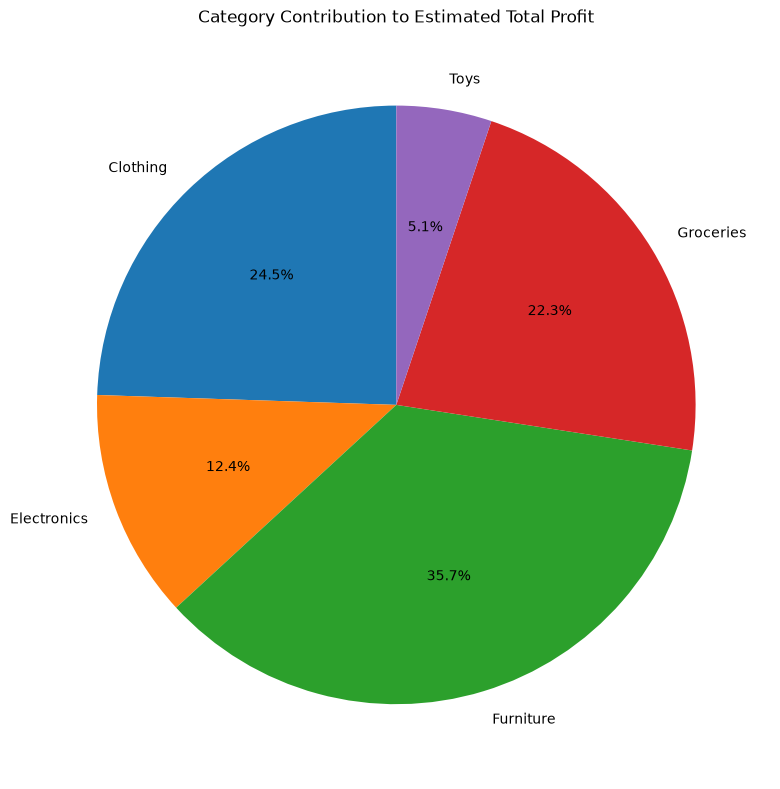

In [24]:
plt.figure(figsize=(8, 8))

plt.pie(
    category_profitability_summary["Profit_Contribution_%"],
    labels=category_profitability_summary.index,
    autopct="%1.1f%%",
    startangle=90
)

plt.title("Category Contribution to Estimated Total Profit")
plt.tight_layout()
plt.show()

In [25]:
category_demand_profit = business_df.groupby("Category").agg(
    Average_Demand=("Demand", "mean"),
    Total_Units_Sold=("Units Sold", "sum")
).join(
    category_profitability_summary[
        ["Estimated_Profit", "Profit_Margin"]
    ]
)

category_demand_profit.round(2).sort_values(
    "Average_Demand", ascending=False
)

,Average_Demand,Total_Units_Sold,Estimated_Profit,Profit_Margin
Category,,,,
Clothing,113.91,233670,5352225.77,33.86
Groceries,113.67,590184,4874821.01,17.29
Electronics,95.59,150693,2705997.50,22.92
Toys,86.46,157013,1124901.56,28.30
Furniture,72.30,174302,7810869.90,39.33


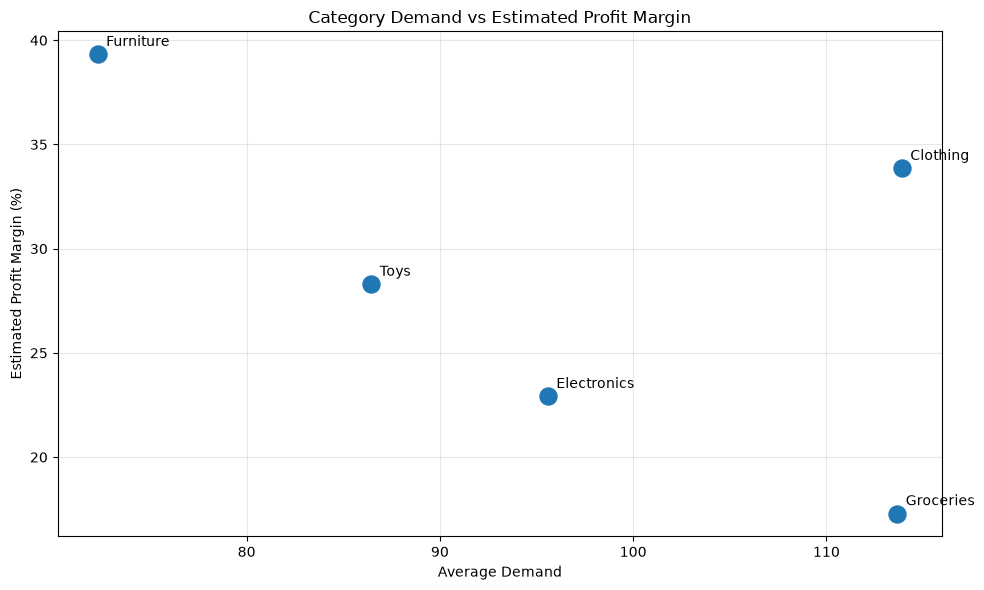

In [26]:
plt.figure(figsize=(10, 6))

plt.scatter(
    category_demand_profit["Average_Demand"],
    category_demand_profit["Profit_Margin"],
    s=150
)

for category in category_demand_profit.index:
    plt.annotate(
        category,
        (
            category_demand_profit.loc[category, "Average_Demand"],
            category_demand_profit.loc[category, "Profit_Margin"]
        ),
        xytext=(6, 6),
        textcoords="offset points"
    )

plt.title("Category Demand vs Estimated Profit Margin")
plt.xlabel("Average Demand")
plt.ylabel("Estimated Profit Margin (%)")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## Category-Level Business Recommendations

### 1. Furniture
- Highest estimated profit and profit margin.
- Maintain focus on pricing discipline and cost control.
- Investigate opportunities to increase demand without sacrificing margins.
- Monitor inventory levels, as furniture has the highest inventory-to-sales ratio.

### 2. Clothing
- Strong average demand and second-highest estimated profit.
- Maintain product availability during periods of stronger demand.
- Review discount strategies to protect profitability.
- Monitor forecast errors, particularly in the South and West regions.

### 3. Groceries
- Highest unit sales and strong average demand.
- Estimated profit margin is relatively low.
- Investigate procurement costs, operating costs and discount practices.
- Improve demand and inventory planning to reduce potential waste.

### 4. Electronics
- Moderate demand and estimated profitability.
- Review pricing against competitor prices.
- Monitor demand forecast accuracy across regions.
- Evaluate promotional effectiveness before increasing discounts.

### 5. Toys
- Lowest estimated total profit contribution.
- Estimated profit margin is relatively healthy.
- Review product assortment and demand patterns.
- Avoid unnecessary discounting that could reduce margins further.

### Overall Management Priority
Prioritize furniture and clothing as major estimated profit contributors, while investigating the relatively low estimated margin in groceries.

These recommendations are preliminary because the profitability calculations use hypothetical cost assumptions and the dataset's price definitions have not been independently verified.

## Store-Level Business Recommendations

### 1. Store S002
- Highest average demand and total units sold.
- Maintain adequate inventory to support demand.
- Monitor its relatively low estimated profit margin.
- Investigate whether category mix and discounting are reducing profitability.

### 2. Store S003
- Second-highest average demand and sales volume.
- Maintain its strong sales performance.
- Monitor inventory allocation and category-level profitability.
- Review opportunities to improve estimated margins.

### 3. Store S005
- Third-highest average demand.
- Furniture and groceries are its largest estimated profit contributors.
- Continue monitoring these categories.
- Investigate opportunities to improve sales and estimated profitability.

### 4. Store S001
- Fourth in average demand and total units sold.
- Furniture is its largest estimated profit contributor.
- Review category-level demand and inventory allocation.
- Investigate opportunities to improve sales performance.

### 5. Store S004
- Lowest average demand and total units sold.
- Highest estimated profit and profit margin.
- Furniture contributes approximately 53.93% of estimated profit.
- Monitor its dependence on furniture and investigate opportunities to diversify profitability.

### Overall Management Priority
S002 and S003 deserve attention for demand and inventory planning, while S004 provides an interesting example of how lower sales volume can coexist with higher estimated profitability.

These recommendations are preliminary and depend on the hypothetical category cost assumptions used in this analysis.

## Pricing and Discount Strategy Recommendations

### 1. Protect Profit Margins
- Avoid excessive discounting that reduces estimated profit per unit.
- Review discount levels separately for each product category.
- Use actual product costs before implementing pricing changes.

### 2. Furniture
- Furniture has the highest estimated profit margin.
- Maintain pricing discipline.
- Test carefully whether selected promotions can increase demand without significantly reducing margins.

### 3. Clothing
- Clothing combines strong demand with relatively high estimated profitability.
- Evaluate targeted promotions rather than applying broad discounts.
- Monitor regional forecast errors when planning promotions.

### 4. Groceries
- Groceries generate the highest unit sales but have a relatively low estimated margin.
- Investigate procurement and operating costs.
- Review discount effectiveness and avoid unnecessary reductions in selling price.

### 5. Electronics and Toys
- Compare selling prices with competitor pricing.
- Evaluate promotional performance using both sales volume and profitability.
- Avoid assuming that higher discounts automatically produce better financial outcomes.

### Important Pricing Limitation
The analysis uses hypothetical category-level cost percentages. The dataset's Price field has not been independently verified as the original list price or actual selling price.

Therefore, these findings are exploratory pricing insights, not validated optimal pricing recommendations.

## Demand Forecasting and Inventory Management Recommendations

### 1. Improve Demand Forecasting
- Use historical demand patterns to support planning.
- Monitor model performance regularly using MAE and RMSE.
- Pay particular attention to Groceries and Clothing, where forecast errors were relatively high.
- Investigate category-region combinations with weaker prediction accuracy.

### 2. Improve Inventory Allocation
- Review inventory levels across stores and product categories.
- Investigate Furniture's relatively high inventory-to-sales ratio.
- Monitor inventory availability in high-demand categories such as Groceries and Clothing.
- Avoid excessive inventory allocation based solely on historical demand.

### 3. Store-Level Planning
- S002 and S003 show relatively high average demand.
- S004 has the highest estimated profit despite lower demand.
- Consider both demand and estimated profitability when evaluating inventory allocation.

### 4. Monitor Forecast Accuracy
- Compare predicted demand against actual demand regularly.
- Investigate systematic overestimation or underestimation.
- Retrain and validate the model as new data becomes available.

### Important Operational Limitation
The dataset's variable definitions and timing have not been independently verified. In particular, the relationship between Demand, Units Sold and Inventory Level requires clarification before using predictions for live replenishment decisions.

The model's historical test performance does not guarantee future forecasting accuracy.

## Business Risks and Analytical Limitations

### 1. Dataset Limitations
- The dataset contains 76,000 records covering five stores and five product categories.
- The dataset's source and real-world representativeness should be verified.
- The currency and precise meaning of the Price variable are not documented in the analysis.

### 2. Profitability Assumptions
- The dataset does not provide verified product-level costs.
- Category-level cost percentages were introduced as hypothetical assumptions.
- Estimated profit and profit margins are illustrative, not actual financial results.
- Operating expenses, taxes, logistics and other costs are not included.

### 3. Demand Forecasting Limitations
- The Random Forest model achieved an R² of approximately 0.743 on the chronological test set.
- Historical performance does not guarantee future accuracy.
- Feature definitions and availability at forecast time require verification.
- Demand prediction errors vary across categories and regions.

### 4. Correlation and Causation
- Relationships between discounts, promotions, prices and demand do not establish causation.
- Other factors may influence observed demand patterns.
- Controlled experiments would be needed to measure the actual effect of pricing and promotions.

### 5. Inventory Limitations
- Inventory-to-sales ratios are diagnostic comparisons, not formal inventory turnover measures.
- The dataset does not establish whether inventory observations represent opening, average or closing stock.
- Potential stockouts and excess inventory require additional operational information.

### 6. Recommendations for Further Improvement
- Obtain verified product-level costs and actual selling prices.
- Confirm dataset definitions and feature timing.
- Include operating expenses and inventory holding costs.
- Validate forecasting performance on newer, unseen data.
- Conduct controlled pricing and promotion experiments.
- Incorporate stockout, replenishment and supplier lead-time information.

# Executive Summary

## Retail Demand, Pricing and Profitability Analysis

### Project Overview

This project examines retail demand patterns, pricing behaviour, inventory indicators and estimated profitability across five stores and five product categories. The analysis combines exploratory data analysis, business performance evaluation, machine learning-based demand prediction and illustrative profitability modelling.

The objective is to demonstrate how data analytics can support more informed retail management decisions.

### Key Findings

**1. Demand Analysis**
- Groceries and clothing recorded the highest average demand.
- Furniture recorded the lowest average demand.
- Demand patterns varied across product categories and regions.

**2. Demand Prediction**
- A Random Forest model achieved an R² of approximately 0.743 on the chronological test dataset.
- The model performed better than the Linear Regression and baseline models evaluated.
- Forecast errors varied across categories and regions, highlighting opportunities for further improvement.

**3. Pricing and Profitability**
- Furniture generated the highest estimated profit contribution at 35.72%.
- Clothing contributed 24.47%.
- Groceries recorded the highest unit sales but a comparatively lower estimated profit margin.
- Profitability estimates rely on hypothetical category-level cost assumptions.

**4. Store Performance**
- S002 recorded the highest average demand and unit sales.
- S004 generated the highest estimated profit and estimated profit margin despite having the lowest average demand.
- Store-level profitability varied with product category composition.

**5. Inventory Management**
- Inventory-to-sales ratios differed across stores and categories.
- Furniture showed the highest category-level ratio.
- These indicators can guide further investigation but do not independently establish overstocking or stockout conditions.

### Management Recommendations

- Protect margins in high-contribution categories such as furniture and clothing.
- Investigate the relatively low estimated grocery margin.
- Improve demand monitoring in categories and regions with higher prediction errors.
- Evaluate inventory allocation using both demand and profitability indicators.
- Validate pricing and promotional decisions using actual costs and controlled experiments.

### Conclusion

The project demonstrates how data exploration, predictive modelling and business-oriented financial analysis can be combined to investigate retail performance.

The findings illustrate that higher demand and sales volume do not necessarily translate into higher profitability. Combining demand forecasts with pricing, inventory and cost information can provide a more comprehensive basis for management decisions.

However, the profitability results are illustrative because verified product costs and price definitions are unavailable. The forecasting model also requires further validation of variable definitions and feature availability before operational deployment.

The project therefore represents an analytical decision-support prototype rather than a fully validated retail optimisation system.

In [27]:
print("PROJECT VALIDATION SUMMARY")
print("-" * 45)

print("Raw dataset shape:", df.shape)
print("Test dataset shape:", business_df.shape)
print("Pricing analysis shape:", pricing_df.shape)

print("\nDemand prediction records:", len(predictions))

print("\nEstimated financial results:")
print(
    "Estimated sales value:",
    round(pricing_df["Estimated_Sales_Value"].sum(), 2)
)
print(
    "Estimated total profit:",
    round(pricing_df["Estimated_Total_Profit"].sum(), 2)
)

overall_margin = (
    pricing_df["Estimated_Total_Profit"].sum()
    / pricing_df["Estimated_Sales_Value"].sum()
) * 100

print("Estimated overall profit margin:", round(overall_margin, 2), "%")

print("\nMissing values in pricing analysis:")
print(
    pricing_df[
        ["Estimated_Selling_Price", "Estimated_Sales_Value",
         "Unit_Cost", "Estimated_Total_Profit"]
    ].isna().sum()
)

PROJECT VALIDATION SUMMARY
---------------------------------------------
Raw dataset shape: (76000, 16)
Test dataset shape: (15200, 17)
Pricing analysis shape: (15200, 21)

Demand prediction records: 15200

Estimated financial results:
Estimated sales value: 79642881.67
Estimated total profit: 21868815.74
Estimated overall profit margin: 27.46 %

Missing values in pricing analysis:
Estimated_Selling_Price    0
Estimated_Sales_Value      0
Unit_Cost                  0
Estimated_Total_Profit     0
dtype: int64
